In [1]:
!pip install ultralytics opencv-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 538.6 kB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 865.2/865.2 kB 2.6 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.6/58.6 MB 1.5 MB/s  0:00:48m0:00:0100:020m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [ultralytics] [ultralytics]platform]


In [13]:
import cv2
import torch
from ultralytics import YOLO

# -------------------------------------------------
# Configuration
# -------------------------------------------------
from pathlib import Path

# ============================================================
# SETTINGS
# ============================================================

VIDEO_PATH = "/home/ayush-ubantu/Downloads/Jamia/Lab/Sem3/MS36/3sep/sintel.mp4"

OUTPUT_PATH = "/home/ayush-ubantu/Downloads/Jamia/Lab/Sem3/MS36/3sep/sintel_output.mp4"


# YOLO11 models:
# yolo11n.pt = fastest
# yolo11s.pt = good balance
# yolo11m.pt = more accurate
# yolo11l.pt = higher accuracy
MODEL_PATH = "yolo11m.pt"

CONFIDENCE_THRESHOLD = 0.35

In [14]:
# -------------------------------------------------
# GPU setup
# -------------------------------------------------

device = 0 if torch.cuda.is_available() else "cpu"

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: False


In [15]:
# -------------------------------------------------
# Load YOLO model
# -------------------------------------------------

model = YOLO(MODEL_PATH)

In [16]:
# -------------------------------------------------
# Open video
# -------------------------------------------------
cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError(f"Could not open video: {VIDEO_PATH}")

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print(f"Resolution: {width}x{height}")
print(f"FPS: {fps}")
print(f"Frames: {frame_count}")

Resolution: 640x360
FPS: 24.0
Frames: 240


[mov,mp4,m4a,3gp,3g2,mj2 @ 0x3b67ef00] Referenced QT chapter track not found


In [17]:
# -------------------------------------------------
# Output video writer
# -------------------------------------------------

fourcc = cv2.VideoWriter_fourcc(*"mp4v")

writer = cv2.VideoWriter(
    OUTPUT_PATH,
    fourcc,
    fps,
    (width, height)
)

In [18]:
# -------------------------------------------------
# Object detection
# -------------------------------------------------

frame_number = 0

while True:

    ret, frame = cap.read()

    if not ret:
        break

    # Run YOLO inference
    
    results = model.predict(
    source=frame,
    device=device,
    conf=CONFIDENCE_THRESHOLD,
    imgsz=640,
    quantize=16 if torch.cuda.is_available() else 32,
    verbose=False
)

    result = results[0]

    # Draw bounding boxes, labels, confidence scores
    annotated_frame = result.plot()

    writer.write(annotated_frame)

    frame_number += 1

    if frame_number % 100 == 0:
        print(
            f"Processed {frame_number}/{frame_count} frames "
            f"({100 * frame_number / frame_count:.1f}%)"
        )

Processed 100/240 frames (41.7%)
Processed 200/240 frames (83.3%)


In [19]:
# -------------------------------------------------
# Cleanup
# -------------------------------------------------

cap.release()
writer.release()

print(f"Done. Saved to: {OUTPUT_PATH}")

Done. Saved to: /home/ayush-ubantu/Downloads/Jamia/Lab/Sem3/MS36/3sep/sintel_output.mp4


# BASICS

Load YOLO and detect objects

Image

     ↓

YOLO model

      ↓

Object detection

        ↓

Bounding boxes + confidence + class

In [4]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

results = model(r"/home/ayush-ubantu/Downloads/Jamia/Lab/Sem3/MS36/3sep/img1.jpg")
#insert your own paths

for result in results:
    result.show()


image 1/1 /home/ayush-ubantu/Downloads/Jamia/Lab/Sem3/MS36/3sep/img1.jpg: 448x640 1 bowl, 2 bananas, 4 apples, 5 oranges, 855.0ms
Speed: 39.2ms preprocess, 855.0ms inference, 50.4ms postprocess per image at shape (1, 3, 448, 640)


# Look inside YOLO's result

In [20]:
# Get the result for the first image

result = results[0]

print(result)
# print(result.boxes)

ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
depth: None
keypoints: None
masks: None
names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'po

In [21]:
# Bounding-box coordinates
# Format:
# [x1, y1, x2, y2]
print(result.boxes.xyxy)

tensor([[274.8188,  43.5403, 579.1925, 313.4740]])


In [22]:
# Confidence score for each detected object

print(result.boxes.conf)

tensor([0.7960])


In [23]:
# Dictionary containing class IDs and class names

print(result.names)

{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'cell phone', 68: 'microw

In [24]:
# Class ID of each detected object

print(results[0].boxes.cls)

tensor([0.])


In [25]:
# Display YOLO's detections

results[0].show()

Step 2 — Manually draw YOLO's bounding boxes

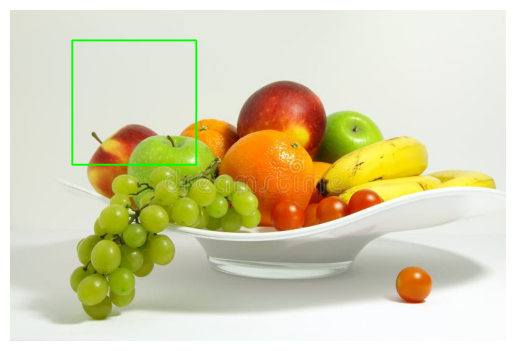

In [27]:
import cv2
import matplotlib.pyplot as plt

image = cv2.imread(r"/home/ayush-ubantu/Downloads/Jamia/Lab/Sem3/MS36/3sep/img1.jpg")

# Draw a rectangle manually
#
# (100, 50)  → top-left corner
# (300, 250) → bottom-right corner
# (0, 255, 0) → green color
# 2          → thickness

cv2.rectangle(
    image,
    (100, 50),
    (300, 250),
    (0, 255, 0),
    2
)

# OpenCV reads images in BGR format.
# Matplotlib expects RGB format.

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image)
plt.axis("off")
plt.show()

# Replace manual coordinates with YOLO coordinates

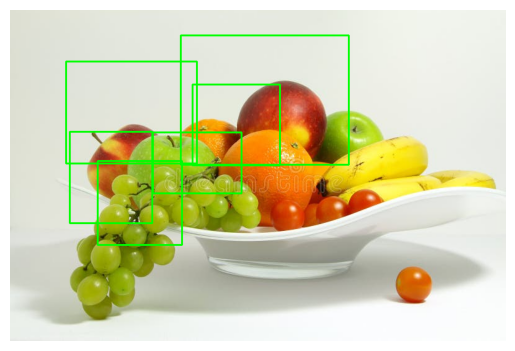

In [28]:
import cv2
import matplotlib.pyplot as plt

image = cv2.imread(r"/home/ayush-ubantu/Downloads/Jamia/Lab/Sem3/MS36/3sep/img1.jpg")

# Bounding boxes obtained from YOLO
boxes = [
    [275.6638, 42.3720, 546.9448, 250.2341],
    [141.1342, 244.1493, 277.2906, 379.3846],
    [294.0269, 121.0689, 435.6662, 251.2020],
    [90.8021, 84.5405, 301.3083, 248.4052],
    [96.1041, 197.6751, 229.2244, 344.6725],
    [230.2206, 198.6188, 373.0497, 296.7406]
]

# Draw a rectangle for every bounding box
for box in boxes:

    x1, y1, x2, y2 = box

    # Convert coordinates from float to integer
    x1 = int(x1)
    y1 = int(y1)
    x2 = int(x2)
    y2 = int(y2)

    cv2.rectangle(
        image,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

# Convert BGR to RGB for Matplotlib
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image)
plt.axis("off")
plt.show()



In [29]:

from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# Load YOLO model
model = YOLO("yolo11n.pt")

# Read image
image = cv2.imread(r"C:\Users\sufis\Downloads\img1.jpg")

# Run YOLO on the image
results = model(image)

# Get the YOLO result
for result in results:

    # Get bounding boxes
    boxes = result.boxes.xyxy

    # Draw every bounding box
    for box in boxes:

        x1, y1, x2, y2 = box

        # Convert coordinates to integers
        x1 = int(x1)
        y1 = int(y1)
        x2 = int(x2)
        y2 = int(y2)

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

# Convert BGR to RGB
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display image
plt.imshow(image)
plt.axis("off")
plt.show()



WARNING ⚠️ 'source' is missing. Using 'source=/home/ayush-ubantu/Downloads/Jamia/Lab/venv/lib/python3.12/site-packages/ultralytics/assets'.


[ WARN:0@3262.777] global loadsave.cpp:278 findDecoder imread_('C:\Users\sufis\Downloads\img1.jpg'): can't open/read file: check file path/integrity



image 1/2 /home/ayush-ubantu/Downloads/Jamia/Lab/venv/lib/python3.12/site-packages/ultralytics/assets/bus.jpg: 640x480 4 persons, 1 bus, 338.8ms
image 2/2 /home/ayush-ubantu/Downloads/Jamia/Lab/venv/lib/python3.12/site-packages/ultralytics/assets/zidane.jpg: 384x640 2 persons, 1 tie, 449.9ms
Speed: 6.9ms preprocess, 394.4ms inference, 5.1ms postprocess per image at shape (1, 3, 384, 640)


error: OpenCV(5.0.0) /io/opencv/modules/imgproc/src/color.cpp:199: error: (-215:Assertion failed) !_src.empty() in function 'cvtColor'


# YOLO finds where the objects are. OpenCV draws the boxes around those objects.